# Decision Tree Algorithm

In [32]:
# Step 1: Importing Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [33]:
# Step 2: Load the Dataset
df = pd.read_csv("decision_tree_dataset.csv")

In [34]:
#  Step 3: Data Observation
df.head()

,age,income,credit_score,city,gender,purchases,loan_amount,approved
0,41,16832.970365,646.435852,Hyderabad,Female,2,NaN,0
1,61,24958.920783,772.103370,Bangalore,Female,2,109037.369348,0
2,29,26661.565307,742.165011,Bangalore,Male,3,140981.063625,0
3,40,76918.367953,789.568381,Mumbai,Female,2,265765.286243,0
4,18,33446.160242,650.679984,Delhi,Male,4,187481.809910,0


In [35]:
# check the info
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1050 entries, 0 to 1049
Data columns (total 8 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   age           1050 non-null   int64  
 1   income        947 non-null    float64
 2   credit_score  946 non-null    float64
 3   city          1050 non-null   object 
 4   gender        1050 non-null   object 
 5   purchases     1050 non-null   int64  
 6   loan_amount   947 non-null    float64
 7   approved      1050 non-null   int64  
dtypes: float64(3), int64(3), object(2)
memory usage: 65.8+ KB


In [36]:
# check the missing values
df.isnull().sum()

age               0
income          103
credit_score    104
city              0
gender            0
purchases         0
loan_amount     103
approved          0
dtype: int64

In [37]:
# shape the datasets
df.shape

(1050, 8)

In [38]:
# check the value counts of the target variable
df['approved'].value_counts()

approved
0    731
1    319
Name: count, dtype: int64

In [39]:
# check the describe 
df.describe()

,age,income,credit_score,purchases,loan_amount,approved
count,1050.000000,947.000000,946.000000,1050.000000,9.470000e+02,1050.000000
mean,43.737143,55807.648029,651.605495,2.934286,2.086066e+05,0.303810
std,15.021797,40021.647680,100.166162,1.603281,1.270517e+05,0.460121
min,18.000000,6556.169327,348.048784,0.000000,-5.768131e+04,0.000000
25%,31.000000,40886.541936,584.998140,2.000000,1.378232e+05,0.000000
50%,44.000000,50967.116222,650.052796,3.000000,1.971923e+05,0.000000
75%,56.000000,60643.014837,718.563117,4.000000,2.598691e+05,1.000000
max,69.000000,445126.233564,969.310757,9.000000,1.233105e+06,1.000000


<Axes: >

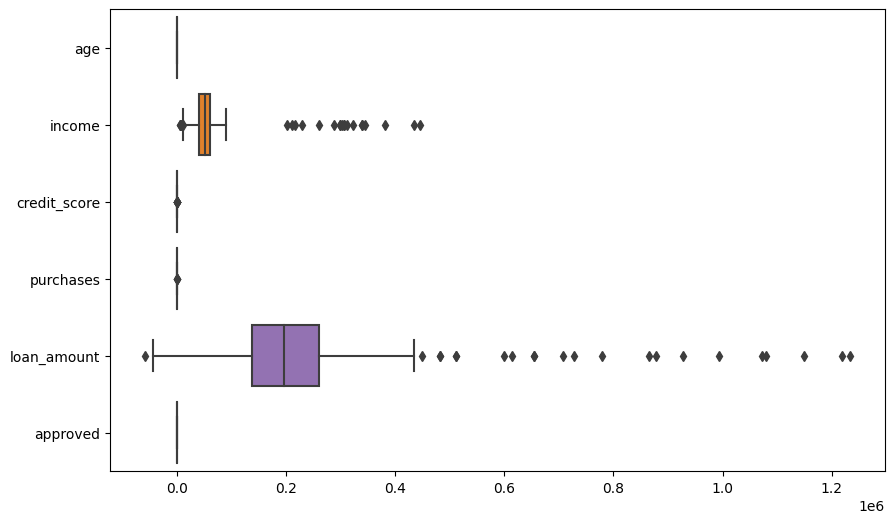

In [40]:
# make the box plot for the numerical columns
plt.figure(figsize=(10,6))

sns.boxplot(data=df, orient='h')

In [41]:
# handled the missing value median 

# income
df['income'] = df['income'].fillna(df['income'].median())

#credit_score
df['credit_score'] =   df['credit_score'].fillna(df['credit_score'].median())

# loan_amount
df['loan_amount'] = df['loan_amount'].fillna(df['loan_amount'].median())

In [42]:
# Handled the outliers using IQR method

outlier_columns = ['income', 'credit_score', 'loan_amount', 'purchases']

for col in outlier_columns:

    # find the Q1, Q3
    Q1 = df[col].quantile(0.25)

    # find the Q3
    Q3 = df[col].quantile(0.75)

    # find the IQR
    IQR = Q3 - Q1

    # find the lower bound and upper bound
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    
    #Apply clipping to the column
    df[col] = df[col].clip(lower_bound, upper_bound)

<Axes: >

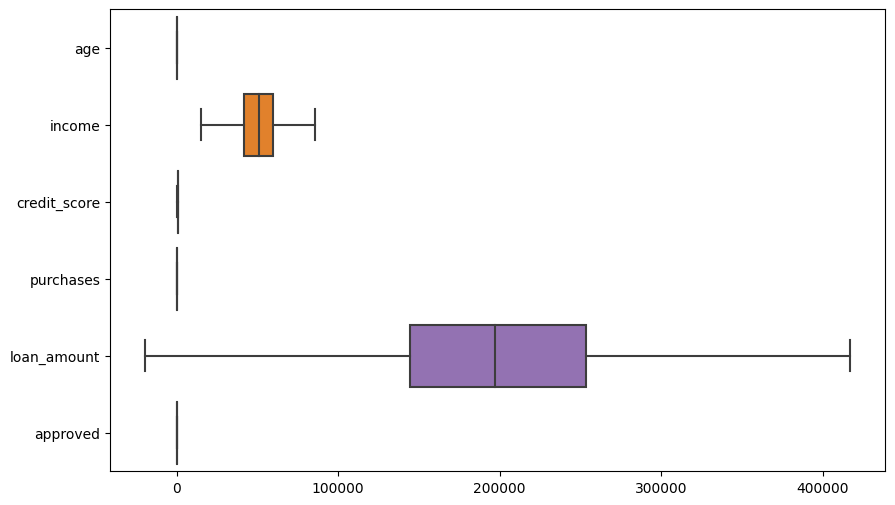

In [43]:
# make the box plot for the numerical columns
plt.figure(figsize=(10,6))

sns.boxplot(data=df, orient='h')

In [44]:
df.head()

,age,income,credit_score,city,gender,purchases,loan_amount,approved
0,41,16832.970365,646.435852,Hyderabad,Female,2,197192.282657,0
1,61,24958.920783,772.103370,Bangalore,Female,2,109037.369348,0
2,29,26661.565307,742.165011,Bangalore,Male,3,140981.063625,0
3,40,76918.367953,789.568381,Mumbai,Female,2,265765.286243,0
4,18,33446.160242,650.679984,Delhi,Male,4,187481.809910,0


In [45]:
# check the unique values of the categorical columns

df['city'].unique()

array(['Hyderabad', 'Bangalore', 'Mumbai', 'Delhi'], dtype=object)

In [46]:
# Replace the Gender column with numerical values
df['gender'] = df['gender'].replace({'Male': 1, 'Female': 0})

C:\Users\ssart\AppData\Local\Temp\ipykernel_9084\660113310.py:2: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df['gender'] = df['gender'].replace({'Male': 1, 'Female': 0})


In [47]:
# apply one hot encoding to the city column
df = pd.get_dummies(df, columns=['city'], drop_first=True)

In [48]:
df.head()


,age,income,credit_score,gender,purchases,loan_amount,approved,city_Delhi,city_Hyderabad,city_Mumbai
0,41,16832.970365,646.435852,0,2,197192.282657,0,False,True,False
1,61,24958.920783,772.103370,0,2,109037.369348,0,False,False,False
2,29,26661.565307,742.165011,1,3,140981.063625,0,False,False,False
3,40,76918.367953,789.568381,0,2,265765.286243,0,False,False,True
4,18,33446.160242,650.679984,1,4,187481.809910,0,True,False,False


In [49]:
# divide the dataset into features and target variable
X = df.drop('approved', axis=1)
y = df['approved']

In [ ]:
# Handle the class imbalance using SMOTE
from imblearn.over_sampling import SMOTE

# create an instance of SMOTE
smote = SMOTE(random_state=42)

# fit and transform the features and target variable
X, y = smote.fit_resample(X, y)

In [50]:
# Handle the class imbalance using RandomOverSampler
from imblearn.over_sampling import RandomOverSampler

# create an instance of RandomOverSampler
ros = RandomOverSampler(random_state=42)

# fit and transform the features and target variable
X, y = ros.fit_resample(X, y)




In [ ]:
# handled the Under Sampling using RandomUnderSampler
from imblearn.under_sampling import RandomUnderSampler

# create an instance of RandomUnderSampler
rus = RandomUnderSampler(random_state=42)

# fit and transform the features and target variable
X, y = rus.fit_resample(X, y)


In [ ]:
#handle the Under Sampling using Edited Nearest Neighbors (ENN)
from imblearn.under_sampling import EditedNearestNeighbours

# create an instance of EditedNearestNeighbours
enn = EditedNearestNeighbours()

# fit and transform the features and target variable
X, y = enn.fit_resample(X, y)

In [52]:
# split the dataset into training and testing sets
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

In [53]:
# model building using Decision Tree Classifier

from sklearn.tree import DecisionTreeClassifier

# create the model
model = DecisionTreeClassifier(
    criterion='gini',
    splitter='best',
    max_depth=5,
    min_samples_split=10,
    min_samples_leaf=5,
    random_state=42
)

# fit the model on the training data
model.fit(X_train, y_train)

# make predictions on the test data
y_pred = model.predict(X_test)


In [54]:
from sklearn.metrics import accuracy_score, classification_report, confusion_matrix

# calculate the accuracy score
accuracy = accuracy_score(y_test, y_pred)

# print the accuracy score
print("Accuracy Score:", accuracy)

# print the classification report
print("\nClassification Report:")
print(classification_report(y_test, y_pred))

# print the confusion matrix
print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))



Accuracy Score: 0.9556313993174061

Classification Report:
              precision    recall  f1-score   support

           0       0.97      0.95      0.96       161
           1       0.94      0.96      0.95       132

    accuracy                           0.96       293
   macro avg       0.95      0.96      0.96       293
weighted avg       0.96      0.96      0.96       293


Confusion Matrix:
[[153   8]
 [  5 127]]


In [55]:
# training accuracy 

training_accuracy = accuracy_score(y_train, model.predict(X_train))
print("Training Accuracy Score:", training_accuracy)

Training Accuracy Score: 0.9828913601368692
